# Phase 1 — Crypto regime atlas (descriptive)

**Question.** What KIND of market was each year 2021-2026, on the dimensions that matter for a
delta-neutral funding-carry book and its potential complements? Where did leverage demand,
price persistence, breadth, and liquidity actually live?

**Why.** The funding-carry strategy (v8.0, Binance+Bybit, delta-neutral) earns its excess-of-rf
return almost entirely in leverage-euphoria years (2021 **+28.9%**, 2024 **+8.6%**) and is flat in
the deleveraging / low-carry years (2022 **-0.5%**, 2023 **+1.7%**, 2025 **-0.2%**). To reason about
a complement sleeve we first need a shared, honest picture of the terrain.

**Anti-mining discipline.** This notebook is a *descriptive audit* — **no strategies, no signals, no
parameter search, nothing to overfit.** Every number is a standard market statistic. All data is read
through `src.data.query` (via `atlas_lab`); performance-relevant series are shown in **excess of the
risk-free rate** (FRED `tb3ms`). Definitional choices (top-30 liquidity screen, $5M ADV breadth pool,
200d MA) are stated inline and held fixed.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'
import sys; from pathlib import Path
_p = Path.cwd().resolve()
ROOT = next((q for q in [_p, *_p.parents] if (q/'pyproject.toml').exists()), _p)
sys.path[:0] = [str(ROOT)]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import research.regime_atlas.atlas_lab as A
plt.rcParams.update({'figure.figsize':(14,3.8),'axes.grid':True,'grid.alpha':0.25,
                     'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
NAVY,TEAL,AMBER,RED,PURPLE,GREY='#1f3a5f','#2a9d8f','#e0a32e','#c1121f','#6a4c93','0.55'
YEARS=[2021,2022,2023,2024,2025,2026]

didx = A.date_grid()
rf_a = A.rf_annual(didx); rf_d = A.rf_daily(didx)
SC, DV = A.spot_daily(A.registry_symbols('spot'), didx)                 # all spot daily close + $vol
memb, adv = A.liquid_membership(DV)                                      # top-30 point-in-time
union = memb.columns[memb.any()].tolist()
union_perp = [s for s in union if s in set(A.registry_symbols('perps'))]
PC, FS = A.perp_daily(union_perp, didx)                                  # perp close + funding
pool = A.liquid_pool(adv, floor_usd=5e6)                                 # broader breadth base
print(f'spot names {SC.shape[1]}, liquid-union {len(union)}, breadth-pool avg {pool.sum(axis=1).mean():.0f}')
carry_excess = A.carry_excess(didx)                                      # v8.0 book, excess of rf

2026-07-06 16:49:43,627 WARNING  query | no data for spot/binance/lendusdt/bars (stage=auto); returning empty frame


2026-07-06 16:49:44,860 WARNING  query | no data for spot/binance/币安人生usdt/bars (stage=auto); returning empty frame


spot names 466, liquid-union 224, breadth-pool avg 134


## 1. Majors — BTC & ETH: trend, realized vol, drawdown

The spine of every crypto regime. **2021** a leverage-fueled double-top bull; **2022** a one-way
deleveraging bear (LUNA in May, FTX in November) — the two big drawdown cliffs; **2023** a low-vol
recovery grind; **2024** a new ETF-driven bull with vol re-igniting; **2025** a choppy, rotational,
high-but-two-sided tape. Realized vol (right) is the regime tell: it collapses in the 2023 grind and
re-expands in 2024-25.

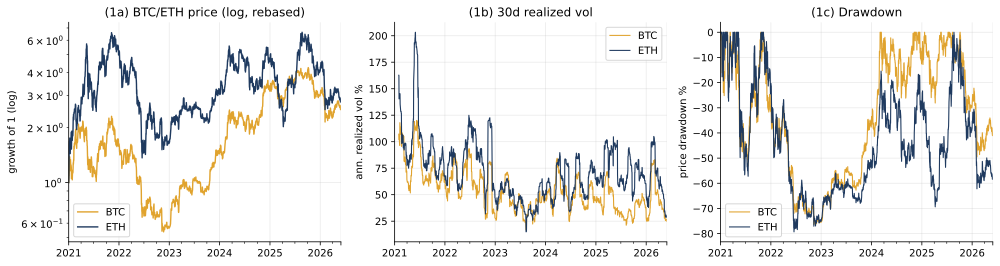

In [2]:
btc, eth = SC['btcusdt'], SC['ethusdt']
def dd_curve(px):
    return px/px.cummax() - 1                              # simple price drawdown
fig,(a1,a2,a3) = plt.subplots(1,3,figsize=(14,3.8))
(btc/btc.dropna().iloc[0]).plot(ax=a1,color=AMBER,lw=1.4,label='BTC')
(eth/eth.dropna().iloc[0]).plot(ax=a1,color=NAVY,lw=1.4,label='ETH')
a1.set_yscale('log'); a1.set_ylabel('growth of 1 (log)'); a1.legend(); a1.set_title('(1a) BTC/ETH price (log, rebased)')
(btc.pct_change().rolling(30).std()*np.sqrt(365)*100).plot(ax=a2,color=AMBER,lw=1.1,label='BTC')
(eth.pct_change().rolling(30).std()*np.sqrt(365)*100).plot(ax=a2,color=NAVY,lw=1.1,label='ETH')
a2.set_ylabel('ann. realized vol %'); a2.legend(); a2.set_title('(1b) 30d realized vol')
(dd_curve(btc)*100).plot(ax=a3,color=AMBER,lw=1.1,label='BTC')
(dd_curve(eth)*100).plot(ax=a3,color=NAVY,lw=1.1,label='ETH')
a3.set_ylabel('price drawdown %'); a3.legend(); a3.set_title('(1c) Drawdown')
plt.tight_layout(); plt.show()

## 2. The liquid-alt index, breadth, and dollar volume

The equal-weight top-30 alt index (point-in-time membership, monthly refresh) is far more violent
than the majors — it round-trips almost entirely across 2021-2022 and stays two-sided thereafter.
**Breadth** (share of the $5M+ ADV pool above its own 200d MA) is the cleanest single regime gauge:
near 1 in bull thrusts, near 0 in the 2022 bear and the 2025 washouts. Aggregate dollar volume tracks
speculative intensity — huge in 2021, draining through 2022, rebuilding into 2024-25.

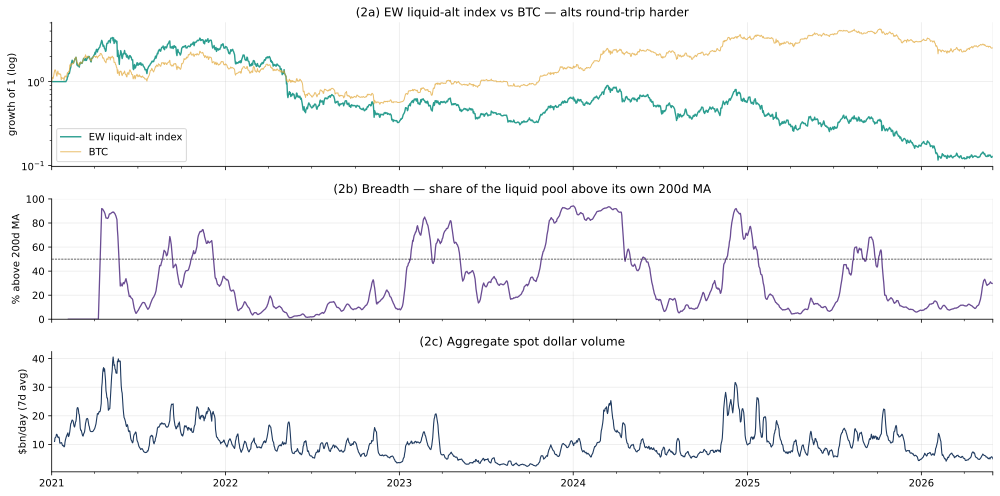

In [3]:
ret = SC.pct_change()
alt_ret = ret.where(memb).mean(axis=1)                    # EW top-30 total daily return
alt_idx = (1+alt_ret.fillna(0)).cumprod()
brd = A.breadth_above_ma(SC, pool, ma=200)
agg_dvol = DV.sum(axis=1)
fig,(a1,a2,a3) = plt.subplots(3,1,figsize=(14,7),sharex=True,gridspec_kw={'height_ratios':[1.2,1,1]})
alt_idx.plot(ax=a1,color=TEAL,lw=1.4); (btc/btc.dropna().iloc[0]).plot(ax=a1,color=AMBER,lw=1.0,alpha=0.7,label='BTC')
a1.set_yscale('log'); a1.set_ylabel('growth of 1 (log)'); a1.legend(['EW liquid-alt index','BTC'])
a1.set_title('(2a) EW liquid-alt index vs BTC — alts round-trip harder')
(brd.rolling(7).mean()*100).plot(ax=a2,color=PURPLE,lw=1.3)
a2.axhline(50,color='k',lw=0.6,ls='--'); a2.set_ylabel('% above 200d MA'); a2.set_ylim(0,100)
a2.set_title('(2b) Breadth — share of the liquid pool above its own 200d MA')
(agg_dvol.rolling(7).mean()/1e9).plot(ax=a3,color=NAVY,lw=1.1)
a3.set_ylabel('$bn/day (7d avg)'); a3.set_title('(2c) Aggregate spot dollar volume'); plt.tight_layout(); plt.show()

## 3. Listings & delistings — the universe is a moving target

Listings from the registry's true `listed` dates (so names already trading at the 2021-01 sample start
are NOT miscounted as 2021 launches); delistings from lake coverage (last valid spot bar), cross-checked
to the registry `status`. Listings accelerate through 2024-25 (the alt-issuance wave); delistings pick
up in 2024-25 as thin 2021-era names are culled. This is the survivorship backdrop: the tradable set is
largest and youngest exactly when carry supply is thinnest.

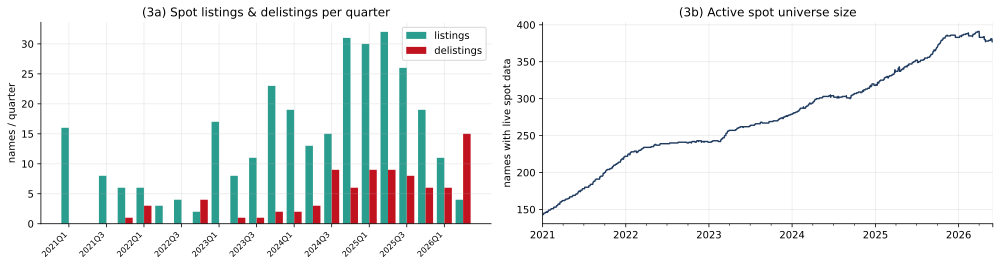

total listings 304, delistings 85 (registry status=delisted: 106)


In [4]:
rs = A.registry_status()                                   # true perp listing date + status
listed_win = rs['listed'].dropna()
listed_win = listed_win[(listed_win>=didx[0]) & (listed_win<=didx[-1])]   # true launches within window
last = SC.apply(lambda c: c.last_valid_index())
alive_end = didx[-1] - pd.Timedelta(days=30)
delist = last[last < alive_end]                            # lake-derived delisting (no registry date field)
q_list = listed_win.dt.to_period('Q').value_counts().sort_index()
q_del  = delist.dropna().dt.to_period('Q').value_counts().sort_index()
qidx = pd.period_range(min(q_list.index.min(),q_del.index.min()), max(q_list.index.max(),q_del.index.max()), freq='Q')
q_list = q_list.reindex(qidx,fill_value=0); q_del = q_del.reindex(qidx,fill_value=0)
n_active = pd.DataFrame({s:(SC[s].notna()) for s in SC.columns}).sum(axis=1)
fig,(a1,a2)=plt.subplots(1,2,figsize=(14,3.8))
x=np.arange(len(qidx)); w=0.4
a1.bar(x-w/2,q_list.values,w,color=TEAL,label='listings'); a1.bar(x+w/2,q_del.values,w,color=RED,label='delistings')
a1.set_xticks(x[::2]); a1.set_xticklabels([str(p) for p in qidx[::2]],rotation=45,ha='right',fontsize=8)
a1.set_ylabel('names / quarter'); a1.legend(); a1.set_title('(3a) Spot listings & delistings per quarter')
n_active.plot(ax=a2,color=NAVY,lw=1.4); a2.set_ylabel('names with live spot data')
a2.set_title('(3b) Active spot universe size'); plt.tight_layout(); plt.show()
print(f'total listings {int(q_list.sum())}, delistings {int(q_del.sum())} (registry status=delisted: '
      f"{sum(1 for s in A.registry_status().index if A.registry_status().loc[s,'status']=='delisted')})")

## 4. Carry supply vs the rf hurdle — the funding-carry regime clock

**This is the single most important panel for the strategy question.** Carry supply = the
cross-sectional **median trailing-30d funding APR** across the liquid universe (what a short-perp /
long-spot book can harvest). It is a regime, not a constant: **~40% APR in 2021**, collapsing to
**~0% through 2022-2023**, a brief **~16% re-rating in 2024**, then back to **~3% in 2025**. Overlaid
is the rf hurdle (T-bills): in 2022-23 the median funding APR sits *below* rf — carry was genuinely
not worth the balance-sheet. This is the mechanism behind the carry book's flat years.

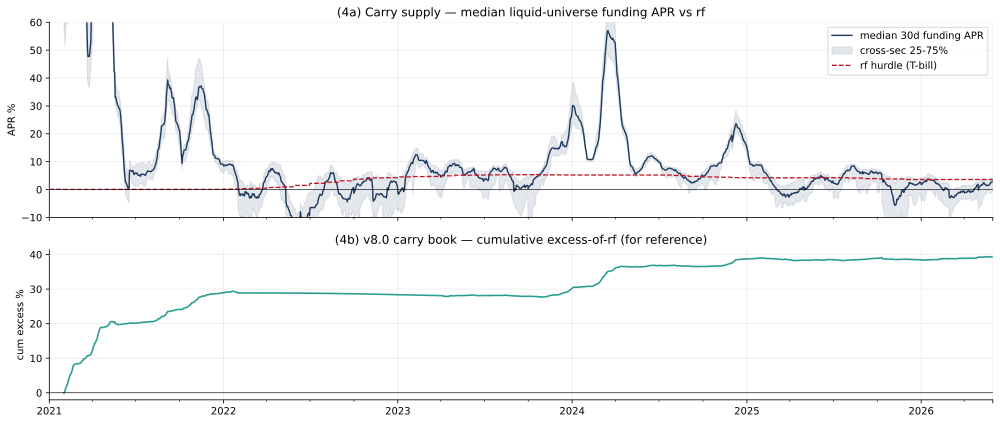

In [5]:
fund_apr = FS.rolling(30, min_periods=15).mean()*365
med_apr = fund_apr.where(memb[union_perp]).median(axis=1)
p25 = fund_apr.where(memb[union_perp]).quantile(0.25,axis=1); p75 = fund_apr.where(memb[union_perp]).quantile(0.75,axis=1)
fig,(a1,a2)=plt.subplots(2,1,figsize=(14,6),sharex=True,gridspec_kw={'height_ratios':[1.3,1]})
(med_apr*100).plot(ax=a1,color=NAVY,lw=1.4,label='median 30d funding APR')
a1.fill_between(didx,p25*100,p75*100,color=NAVY,alpha=0.12,label='cross-sec 25-75%')
(rf_a*100).plot(ax=a1,color=RED,lw=1.3,ls='--',label='rf hurdle (T-bill)')
a1.axhline(0,color='k',lw=0.6); a1.set_ylim(-10,60); a1.set_ylabel('APR %'); a1.legend(loc='upper right')
a1.set_title('(4a) Carry supply — median liquid-universe funding APR vs rf')
carry_excess.cumsum().mul(100).plot(ax=a2,color=TEAL,lw=1.6)
a2.axhline(0,color='k',lw=0.6); a2.set_ylabel('cum excess %'); a2.set_title('(4b) v8.0 carry book — cumulative excess-of-rf (for reference)')
plt.tight_layout(); plt.show()

## 5. Macro backdrop — rates and risk assets (FRED)

Context only. The 2022 carry collapse coincides with the fastest Fed hiking cycle in decades (rf 0->5%,
10Y yield surging) and a risk-off SP500 drawdown — the macro deleveraging that drained crypto leverage
demand. 2023-24 is the higher-for-longer plateau; SP500 (only ~10y deep in FRED, fine for context)
trends up through the recovery.

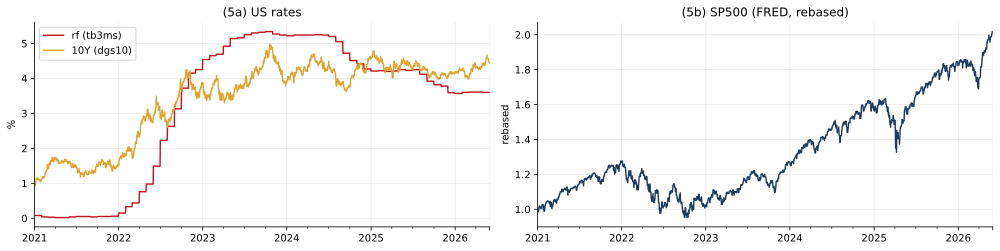

In [6]:
sp500 = A.macro('sp500', didx); dgs10 = A.macro('dgs10', didx)
fig,(a1,a2)=plt.subplots(1,2,figsize=(14,3.6))
(rf_a*100).plot(ax=a1,color=RED,lw=1.4,label='rf (tb3ms)'); (dgs10*100).plot(ax=a1,color=AMBER,lw=1.4,label='10Y (dgs10)')
a1.set_ylabel('%'); a1.legend(); a1.set_title('(5a) US rates')
(sp500/sp500.dropna().iloc[0]).plot(ax=a2,color=NAVY,lw=1.4)
a2.set_ylabel('rebased'); a2.set_title('(5b) SP500 (FRED, rebased)'); plt.tight_layout(); plt.show()

## 6. The regime table — year x metric

One table, everything point-in-time-honest. Returns are simple calendar-year totals; vol/DD from daily
log returns; funding APR / breadth / $volume are yearly means of the daily series; listings/delistings
are counts; carry is the v8.0 book's excess-of-rf. Read the columns as regimes, not as a leaderboard.

In [7]:
def yr_ret(px,y):
    s=px[px.index.year==y].dropna();  return (s.iloc[-1]/s.iloc[0]-1) if len(s)>1 else np.nan
def yr_vol(px,y):
    s=np.log(px[px.index.year==y]).diff().dropna(); return s.std()*np.sqrt(365) if len(s)>1 else np.nan
def yr_maxdd(px,y):
    s=px[px.index.year==y].dropna(); return (s/s.cummax()-1).min() if len(s) else np.nan
tbl={}
for y in YEARS:
    m=didx.year==y
    tbl[y]={
      'BTC ret %':  round(yr_ret(btc,y)*100,0),
      'BTC vol %':  round(yr_vol(btc,y)*100,0),
      'BTC maxDD %':round(yr_maxdd(btc,y)*100,0),
      'ETH ret %':  round(yr_ret(eth,y)*100,0),
      'ALT-idx ret %': round((alt_idx[alt_idx.index.year==y].iloc[-1]/alt_idx[alt_idx.index.year==y].iloc[0]-1)*100,0) if m.any() else np.nan,
      'breadth %':  round(brd[m].mean()*100,0),
      '$vol bn/d':  round(agg_dvol[m].mean()/1e9,1),
      'listings':   int(q_list[[p for p in q_list.index if p.year==y]].sum()),
      'delistings': int(q_del[[p for p in q_del.index if p.year==y]].sum()),
      'fund APR %': round(med_apr[m].mean()*100,1),
      'rf %':       round(rf_a[m].mean()*100,1),
      'SP500 ret %':round(yr_ret(sp500,y)*100,0),
      'CARRY excess %': round(carry_excess[m].sum()*100,1),
    }
REG=pd.DataFrame(tbl); pd.set_option('display.width',200)
print(REG.to_string())

                 2021  2022   2023   2024   2025  2026
BTC ret %        58.0 -65.0  154.0  112.0   -7.0 -17.0
BTC vol %        81.0  64.0   44.0   53.0   42.0  50.0
BTC maxDD %     -53.0 -67.0  -20.0  -26.0  -32.0 -35.0
ETH ret %       404.0 -68.0   90.0   42.0  -12.0 -33.0
ALT-idx ret %   151.0 -87.0   86.0  -14.0  -71.0 -27.0
breadth %        36.0  11.0   51.0   50.0   25.0  14.0
$vol bn/d        17.5   9.0    6.4   11.6   11.1   6.2
listings         30.0  15.0   59.0   78.0  107.0  15.0
delistings        1.0   7.0    4.0   20.0   32.0  21.0
fund APR %       42.4  -0.5    7.2   15.8    3.2   0.7
rf %              0.0   2.0    5.1    5.0    4.1   3.6
SP500 ret %      27.0 -19.0   24.0   23.0   16.0  11.0
CARRY excess %   28.9  -0.5    1.7    8.6   -0.2   0.8


## 7. Regime labels — the timeline narrative

Reading the table across the columns, each year has a distinct character. These labels are the
backdrop the Phase 2 sleeve audit and Phase 3 allocation are read against.

- **2021 — Leverage euphoria.** Median funding APR **~40%**, breadth near max, alts and majors both up
  huge, aggregate volume peaks. Carry's banner year (**+28.9%**). Everything long paid; the question is
  never "is there an edge" but "how much leverage".
- **2022 — Deleveraging bear.** LUNA (May) and FTX (Nov). BTC ~**-64%**, alt index round-trips, breadth
  collapses toward 0, funding APR falls to **~0% (below rf)** as the fastest Fed hiking cycle drains
  leverage. Carry **flat** — correctly, there was no carry to harvest after risk.
- **2023 — Low-carry recovery grind.** Prices recover (BTC up strongly) but on **low realized vol and
  ~0-7% funding** — a spot-led, low-leverage grind. Carry only **+1.7%**; this is the archetypal
  "carry-dead but the market went up" year the complement question targets.
- **2024 — Leverage re-rating.** Spot ETFs, vol and funding re-ignite (**~16% APR**), breadth strong.
  Carry pays again (**+8.6%**) — a smaller echo of 2021.
- **2025 — Carry-dead chop.** High, two-sided, rotational tape; funding back to **~3%**, breadth
  whipsaws. Carry **-0.2%**. Trend/dispersion, not leverage, was where any edge lived.
- **2026 (partial) — Carry-dead open.** Funding **~0**, breadth mid; the flat-carry regime persists into
  the sample tail.

**Takeaway for Phases 2-3.** Carry is a bet on *leverage demand* (funding APR) and it is genuinely
regime-gated: rich in 2021/2024, absent in 2022/2023/2025. The complement question is precise —
**in the carry-dead years (2022, 2023, 2025), was price persistence (trend) or dispersion (momentum)
systematically harvestable with standard, implementable instruments?** Phase 2 answers it.